In [ ]:
!pip install llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu124
!pip install -q pymupdf
!pip install -q easyocr
!pip install -q pillow
!pip install -q huggingface_hub

Looking in indexes: https://pypi.org/simple, https://abetlen.github.io/llama-cpp-python/whl/cu124
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 GB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 83.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 64.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.6/299.6 kB 29.7 MB/s eta 0:00:00


In [ ]:
from huggingface_hub import hf_hub_download

model_path = hf_hub_download(
    repo_id="unsloth/gemma-4-E2B-it-qat-GGUF",
    filename="gemma-4-E2B-it-qat-UD-Q4_K_XL.gguf"
)

print(model_path)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


gemma-4-E2B-it-qat-UD-Q4_K_XL.gguf:   0%|          | 0.00/2.62G [00:00<?, ?B/s]

/root/.cache/huggingface/hub/models--unsloth--gemma-4-E2B-it-qat-GGUF/snapshots/471556aa1b88350ef3540680ce471e9e742b989e/gemma-4-E2B-it-qat-UD-Q4_K_XL.gguf


In [ ]:
from llama_cpp import Llama

llm = Llama(
    model_path=model_path,
    n_ctx=16384,
    n_gpu_layers=-1,
    n_batch=1024,
    verbose=False
)

print("Model Loaded")

llama_context: n_ctx_seq (16384) < n_ctx_train (131072) -- the full capacity of the model will not be utilized
llama_kv_cache_iswa: using full-size SWA cache (ref: https://github.com/ggml-org/llama.cpp/pull/13194#issuecomment-2868343055)
llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 512
llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 512


Model Loaded


In [ ]:
response = llm.create_chat_completion(
    messages=[
        {
            "role": "user",
            "content": "Reply only with OK"
        }
    ],
    max_tokens=10
)

print(
    response["choices"][0]["message"]["content"]
)

OK


In [ ]:
from google.colab import files

uploaded = files.upload()

pdf_path = next(iter(uploaded))

print(pdf_path)

Saving code-de-la-route-marocain-ar.pdf to code-de-la-route-marocain-ar.pdf
code-de-la-route-marocain-ar.pdf


In [ ]:
import fitz
import os

os.makedirs(
    "pages",
    exist_ok=True
)

doc = fitz.open(pdf_path)

for i in range(len(doc)):

    page = doc.load_page(i)

    pix = page.get_pixmap(
        matrix=fitz.Matrix(2.5, 2.5),
        alpha=False
    )

    pix.save(
        f"pages/page_{i+1}.png"
    )

print("Pages:", len(doc))

Pages: 126


In [ ]:
import os

sorted(
    os.listdir("pages")
)[:5]

['page_1.png', 'page_10.png', 'page_100.png', 'page_101.png', 'page_102.png']

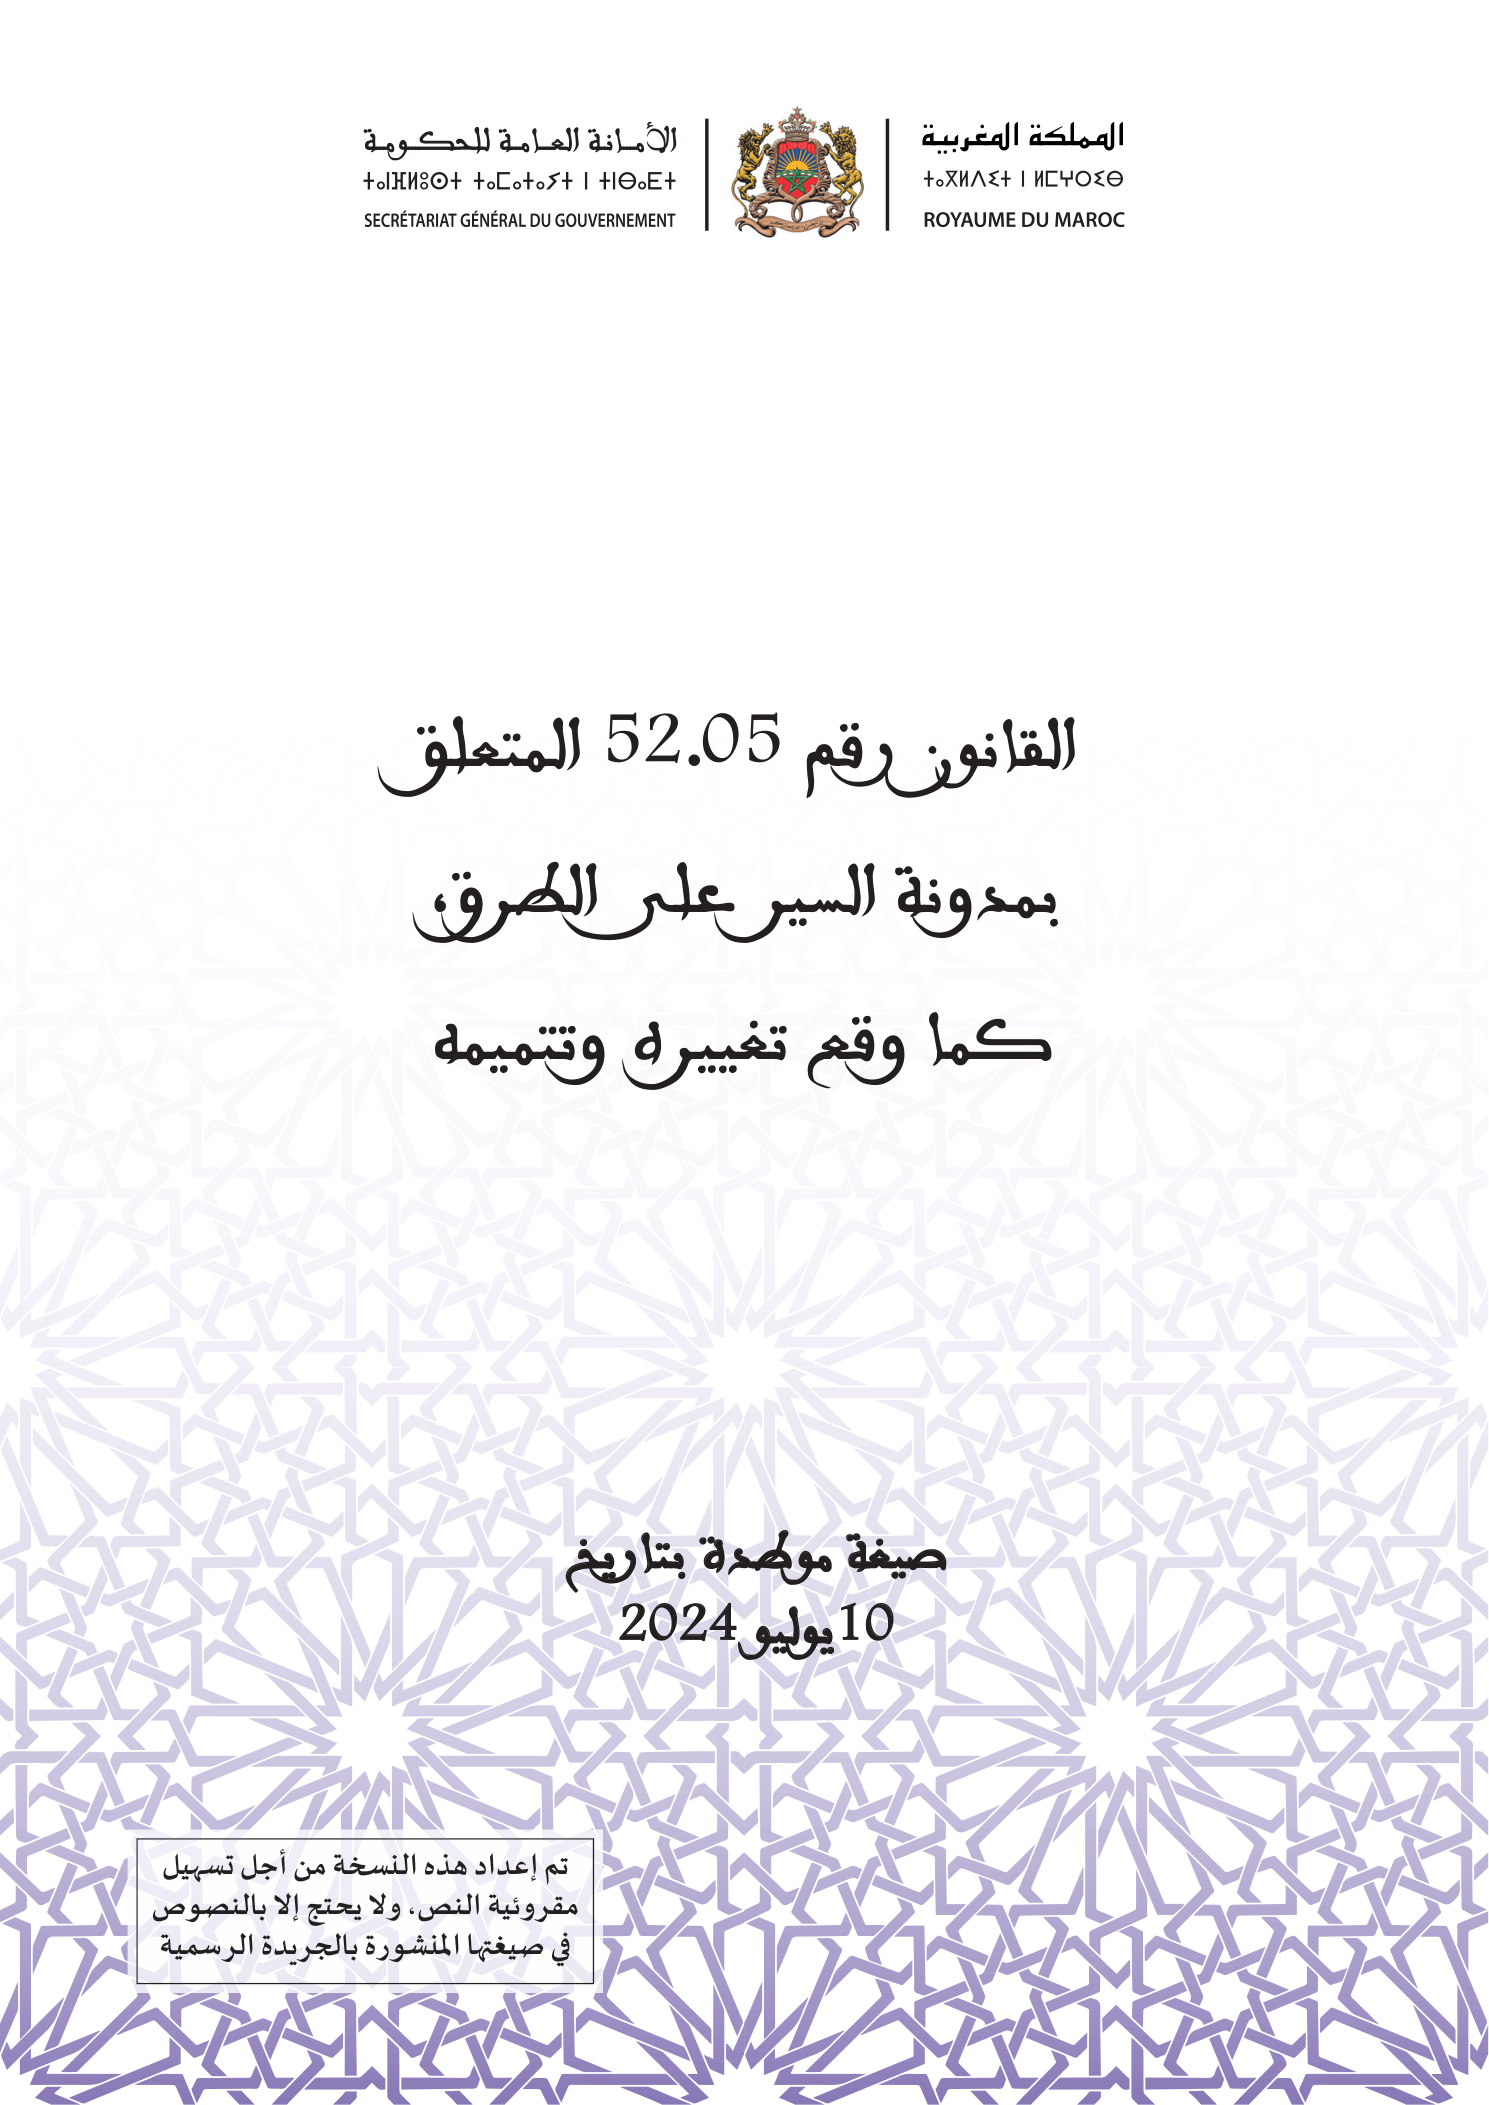

In [ ]:
from PIL import Image

Image.open(
    "pages/page_1.png"
)

In [ ]:
import easyocr

reader = easyocr.Reader(
    ['ar'],
    gpu=True
)

print("OCR Ready")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteOCR Ready


In [ ]:
result = reader.readtext(
    "pages/page_1.png",
    detail=0,
    paragraph=True
)

page_text = "\n".join(result)

print(page_text)

الأمانة العامة للحكومة +|9.٤+ +|}[#80+ +.[+>+ 5ع٥عا8عل0ى ٥٧ [6٤٤8٥ حطإ٥ح[٤8 
المملكة المغربية |['0<٥ +٨#^<- ~0إ^ ٥٧ ٤سط0 
القانون رقم 52.05 المتعلق بمدونة السيرعلى الصرق كما وقع تغييره وتتميمه
صيغة موصمة بتاريخ 10 يوليو 2024
تم إعداد هذه النسخة من أجل تسهيل مقروئية النص  ولا يحتج إلا بالنصوص في صيغتها المذشورة بالجريدة الرسمية خمطخ


In [ ]:
import glob
import re

def page_number(path):
    return int(
        re.search(
            r"page_(\d+)\.png",
            path
        ).group(1)
    )

pages_ocr = []

for img in sorted(
    glob.glob("pages/*.png"),
    key=page_number
):

    page_num = page_number(img)

    text = "\n".join(
        reader.readtext(
            img,
            detail=0,
            paragraph=True
        )
    )

    pages_ocr.append({
        "page": page_num,
        "text": text
    })

    print(f"Done page {page_num}")

Done page 1
Done page 2
Done page 3
Done page 4
Done page 5
Done page 6
Done page 7
Done page 8
Done page 9
Done page 10
Done page 11
Done page 12
Done page 13
Done page 14
Done page 15
Done page 16
Done page 17
Done page 18
Done page 19
Done page 20
Done page 21
Done page 22
Done page 23
Done page 24
Done page 25
Done page 26
Done page 27
Done page 28
Done page 29
Done page 30
Done page 31
Done page 32
Done page 33
Done page 34
Done page 35
Done page 36
Done page 37
Done page 38
Done page 39
Done page 40
Done page 41
Done page 42
Done page 43
Done page 44
Done page 45
Done page 46
Done page 47
Done page 48
Done page 49
Done page 50
Done page 51
Done page 52
Done page 53
Done page 54
Done page 55
Done page 56
Done page 57
Done page 58
Done page 59
Done page 60
Done page 61
Done page 62
Done page 63
Done page 64
Done page 65
Done page 66
Done page 67
Done page 68
Done page 69
Done page 70
Done page 71
Done page 72
Done page 73
Done page 74
Done page 75
Done page 76
Done page 77
Done pag

In [ ]:
pages_ocr = sorted(
    pages_ocr,
    key=lambda x: x["page"]
)

merged_text = ""

for page in pages_ocr:

    merged_text += (
        f"\n<<PAGE_{page['page']}>>\n"
    )

    merged_text += page["text"]

In [ ]:
import json

with open(
    "pages_ocr.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        pages_ocr,
        f,
        ensure_ascii=False,
        indent=2
    )

In [ ]:
import re

article_matches = list(
    re.finditer(
        r"المادة\s+\d+",
        merged_text
    )
)

print(
    "Articles found:",
    len(article_matches)
)

Articles found: 535


In [ ]:
for m in article_matches[:20]:
    print(
        m.group()
    )

المادة 1
المادة 2
المادة 3
المادة 4
المادة 2
المادة 5
المادة 10
المادة 11
المادة 6
المادة 7
المادة 8
المادة 7
المادة 309
المادة 9
المادة 10
المادة 11
المادة 251
المادة 12
المادة 13
المادة 7


In [ ]:
import re

article_matches = list(
    re.finditer(
        r"(?m)^المادة\s+\d+",
        merged_text
    )
)

print(
    "Articles found:",
    len(article_matches)
)

Articles found: 253


In [ ]:
for m in article_matches[:20]:
    print(
        repr(
            merged_text[
                m.start():m.start()+50
            ]
        )
    )

'المادة 1\nلا يجوز لأي شخص أن يسوق مركبة ذات محرك أو'
'المادة 2\nاستثنا من أحكام المادة الأولى أعلاه : 1 ي'
'المادة 3\nيجب على السائقين الحاصلين على رخصة سياقة '
'المادة 4\nفى حالة السير الدولي ووفقا للاتفاقية الدو'
'المادة 5\n)غيرت وتممت بموجب امادة الأولى من القانون'
'المادة 6\nلا يجوز لأيكان سياقة مركبة فلاحية ذات محر'
'المادة 7\n)غيرت وتممت بموجب امادة الأولى من القانون'
'المادة 8\nرغيرت وتممت بموجب المادة الأولى من القانو'
'المادة 9\nيجب الإدلا برخصة السياقة أو بالوثيقة التي'
'المادة 12\nيخضع وجوباكل مترشح لاختبارات امتحان الحص'
'المادة 16\nتجرى الفحوص الطبية الإجبارية المفروضة بم'
'المادة 17\n) نسخت وعوضت بموجب امادة الثانية من القا'
'المادة 19\nإذا نازع صاحب رخصة السياقة أو الإدارة في'
'المادة 23\n) نسخت وعوضت بموجب امادة الثانية من القا'
'المادة 24\n)نسخت وعوضت بموجب امادة الثانية من القان'
'المادة 25\n)نسخت بموجب امادة الرابعة من القانون رقم'
'المادة 26\nيجب على صاحب رخصة السياقة  الذي فقد خلال'
'المادة 27 )غيرت بموجب المادة الأولى من القانون رقم'
'المادة 30\n) غيرت بموجب اماد

In [ ]:
articles = []

for i, match in enumerate(article_matches):

    start = match.start()

    if i < len(article_matches)-1:
        end = article_matches[i+1].start()
    else:
        end = len(merged_text)

    article_text = merged_text[start:end].strip()

    articles.append(article_text)

print(
    "Extracted:",
    len(articles)
)

Extracted: 253


In [ ]:
import re

article_objects = []

for article in articles:

    first_line = article.splitlines()[0].strip()

    match = re.match(
        r"المادة\s+(\d+)",
        first_line
    )

    if not match:
        continue

    article_number = int(
        match.group(1)
    )

    article_objects.append({
        "article_number": article_number,
        "text": article
    })

print(
    article_objects[0]["article_number"]
)

1


In [ ]:
for article in article_objects[:20]:

    print(
        "=" * 50
    )

    print(
        article["article_number"]
    )

    print(
        article["text"][:300]
    )

1
المادة 1
لا يجوز لأي شخص أن يسوق مركبة ذات محرك أومجموعة مركبات على الطريق العمو مية مالم يكن حاصلا على رخصة للسياقة سارية الصلاحية ومسلمة من قبل الإدارة  تناسب صنف المركبة أومجموعة المركبات التي يسوقها.
2
المادة 2
استثنا من أحكام المادة الأولى أعلاه : 1 يجوز للمغاربة القا اطنين بالخارج أن يسوقواء داخل التراب الوطنيء خلال مدة أقصاها سنة واحدة ابتدا من إقا امتهم بالمغربء بواسطة رخصة السياقة المسلمة لهم بالخارج سارية الصلاحية
2 - يجوز للسائقين من جنسية أجنبية. أن يسوقوا بواسطة رخصة السياقة المسلمة لهم ب
3
المادة 3
يجب على السائقين الحاصلين على رخصة سياقة مسلمة بالخارج  بعد انصرام المدة المشار إليها في المادة السابقة. أن يتقدموا لامتحانات الحصول على رخصة السياقة المغربية. أوأن يطلبوا تبديل رخصتهم للسياقة تطبيقا للفقر ات الموالية. يمكن للمغاربة والأجانب الحاصلين على رخصة سياقة مسلمة من قبل دولة يربطها 
4
المادة 4
فى حالة السير الدولي ووفقا للاتفاقية الدولية للسير على الطرق  تسلم الهيئات المؤهلة لذلك من قبل الإدارة  رخصة دولية للسياقة موضوعة في دفتر خاص . يجوز للسائقين من جنسية أجنبية الح

In [ ]:
article = article_objects[0]["text"]

prompt = f"""
You are correcting OCR errors in a Moroccan legal document.

Rules:

- Keep Arabic.
- Do not summarize.
- Do not rewrite.
- Do not change legal meaning.
- Do not add missing information.
- Only fix obvious OCR mistakes.

Return corrected text only.

TEXT:

{article}
"""

In [ ]:
response = llm.create_chat_completion(
    messages=[
        {
            "role": "user",
            "content": prompt
        }
    ],
    temperature=0.0,
    max_tokens=2048
)

clean_article = response["choices"][0]["message"]["content"]

print(clean_article)

المادة 1
لا يجوز لأي شخص أن يسوق مركبة ذات محرك أو مجموعة مركبات على الطريق العمومي مئة مالم يكن حاصلا على رخصة للسياقة سارية الصلاحية ومسلمة من قبل الإدارة تناسب صنف المركبة أو مجموعة المركبات التي يسوقها.


In [ ]:
def clean_article(article_text):

    prompt = f"""
You are correcting OCR errors.

Rules:
- Keep Arabic.
- No translation.
- No summary.
- No explanation.
- No comments.
- Return only corrected text.

TEXT:

{article_text}
"""

    response = llm.create_chat_completion(
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.0,
        max_tokens=2048
    )

    return response["choices"][0]["message"]["content"]

In [ ]:
clean_articles = []

for article in article_objects[:5]:

    corrected = clean_article(
        article["text"]
    )

    clean_articles.append({
        "article_number":
            article["article_number"],
        "text":
            corrected
    })

    print(
        "Done",
        article["article_number"]
    )

Done 1
Done 2
Done 3
Done 4
Done 5


In [ ]:
print(
    article_objects[1]["text"]
)

المادة 2
استثنا من أحكام المادة الأولى أعلاه : 1 يجوز للمغاربة القا اطنين بالخارج أن يسوقواء داخل التراب الوطنيء خلال مدة أقصاها سنة واحدة ابتدا من إقا امتهم بالمغربء بواسطة رخصة السياقة المسلمة لهم بالخارج سارية الصلاحية
2 - يجوز للسائقين من جنسية أجنبية. أن يسوقوا بواسطة رخصة السياقة المسلمة لهم بالخارج سارية الصلاحية لكن فقطء خلال مدة أقصاهاسنة من تاريخ إقامتهم المؤقتة بالمغرب كماهي محددة في النصو ص التشريعية والتنظيمية المتعلقة بدخول وإقامة الأجانب بالمملكة المغربية.
<<PAGE_3>>
الأمانة العامة للحكومة


In [ ]:
numbers = [
    a["article_number"]
    for a in article_objects
]

for i in range(len(numbers)-1):

    current_num = numbers[i]
    next_num = numbers[i+1]

    if next_num != current_num + 1:

        print(
            f"Gap: {current_num} -> {next_num}"
        )

Gap: 9 -> 12
Gap: 12 -> 16
Gap: 17 -> 19
Gap: 19 -> 23
Gap: 27 -> 30
Gap: 44 -> 46
Gap: 51 -> 53
Gap: 61 -> 61
Gap: 66 -> 70
Gap: 70 -> 74
Gap: 74 -> 76
Gap: 79 -> 81
Gap: 81 -> 84
Gap: 108 -> 111
Gap: 113 -> 118
Gap: 121 -> 126
Gap: 126 -> 129
Gap: 129 -> 132
Gap: 132 -> 134
Gap: 140 -> 142
Gap: 142 -> 144
Gap: 149 -> 151
Gap: 151 -> 1
Gap: 1 -> 154
Gap: 155 -> 157
Gap: 162 -> 162
Gap: 164 -> 164
Gap: 166 -> 1
Gap: 2 -> 167
Gap: 167 -> 169
Gap: 173 -> 176
Gap: 182 -> 184
Gap: 185 -> 187
Gap: 187 -> 189
Gap: 189 -> 191
Gap: 197 -> 199
Gap: 199 -> 201
Gap: 215 -> 217
Gap: 228 -> 230
Gap: 241 -> 244
Gap: 247 -> 251
Gap: 251 -> 253
Gap: 255 -> 255
Gap: 258 -> 261
Gap: 267 -> 267
Gap: 279 -> 279
Gap: 281 -> 284
Gap: 284 -> 286
Gap: 286 -> 288
Gap: 288 -> 290
Gap: 296 -> 298
Gap: 298 -> 300
Gap: 300 -> 304


In [ ]:
from collections import Counter

counter = Counter(
    numbers
)

duplicates = {
    k:v
    for k,v in counter.items()
    if v > 1
}

print(duplicates)

{1: 3, 2: 2, 61: 2, 162: 2, 164: 2, 255: 2, 267: 2, 279: 2}


In [ ]:
for article in article_objects:

    count = article["text"].count("المادة")

    if count > 3:

        print(
            "Suspicious:",
            article["article_number"]
        )

        print(
            article["text"][:1000]
        )

        print("-"*50)

Suspicious: 5
المادة 5
)غيرت وتممت بموجب امادة الأولى من القانون رقم 116.14 الصادر بتنفيذه الظهير الشريف رقم 116106 بتاريخ 13 من شوال 1437 18 يوليو 2016 ( جر عدد 6490 بتاريخ 7 ذي القعدة 1437)11 أغسطس 2016(. ص: 5866( استثنا من أحكام المادة الأولى أعلاه يجوز للسائقين العسكريين الحاصلين على إجازة السياقة المسلمة من قبل السلطة التابعين لهاء من أجل سياقة المركبات العسكرية : 1 - أن يسوقواء على الطريق العمو مية المركبات العسكرية التي عهد  إليهم بسياقتها من قبل السلطة العسكرية المختصة شريطة احترام قواعد السير المحددة فيهذا القانون والنصوص المتخذة لتطبيقه والقواعد المقررة في شأنهم من قبل السلطة العسكرية 2 - أن يقوموا بتبديل الإجازة مقابل رخصة للسياقة من نفس الصنف مسلمة من قبل الإدارة المدنية   وفقا للشروط المحددة بنص تنظيمي  دون اجتياز الاختبارين المشار إليهما في المادة 10 أسفله شريطة استيفائهم الشروط المحددة في البندين 1 و2 من المادة 11 أسفله
2
<<PAGE_4>>
الأمانة العامة للحكومة
--------------------------------------------------
Suspicious: 8
المادة 8
رغيرت وتممت بموجب المادة الأولى من القانون 

In [ ]:
import json

with open(
    "validated_articles.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        article_objects,
        f,
        ensure_ascii=False,
        indent=2
    )

In [ ]:
import os
import json

CHECKPOINT = "clean_articles.json"

if os.path.exists(CHECKPOINT):

    with open(
        CHECKPOINT,
        "r",
        encoding="utf-8"
    ) as f:

        clean_articles = json.load(f)

else:

    clean_articles = []

In [ ]:
processed = {
    a["article_number"]
    for a in clean_articles
}

print(
    "Already processed:",
    len(processed)
)

Already processed: 0


In [ ]:
for article in article_objects:

    num = article["article_number"]

    if num in processed:
        continue

    corrected = clean_article(
        article["text"]
    )

    clean_articles.append({
        "article_number": num,
        "text": corrected
    })

    with open(
        CHECKPOINT,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            clean_articles,
            f,
            ensure_ascii=False,
            indent=2
        )

    print(
        "Processed",
        num
    )

Processed 1
Processed 2
Processed 3
Processed 4
Processed 5
Processed 6
Processed 7
Processed 8
Processed 9
Processed 12
Processed 16
Processed 17
Processed 19
Processed 23
Processed 24
Processed 25
Processed 26
Processed 27
Processed 30
Processed 31
Processed 32
Processed 33
Processed 34
Processed 35
Processed 36
Processed 37
Processed 38
Processed 39
Processed 40
Processed 41
Processed 42
Processed 43
Processed 44
Processed 46
Processed 47
Processed 48
Processed 49
Processed 50
Processed 51
Processed 53
Processed 54
Processed 55
Processed 56
Processed 57
Processed 58
Processed 59
Processed 60
Processed 61
Processed 61
Processed 62
Processed 63
Processed 64
Processed 65
Processed 66
Processed 70
Processed 74
Processed 76
Processed 77
Processed 78
Processed 79
Processed 81
Processed 84
Processed 85
Processed 86
Processed 87
Processed 88
Processed 89
Processed 90
Processed 91
Processed 92
Processed 93
Processed 94
Processed 95
Processed 96
Processed 97
Processed 98
Processed 99
Processe